# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

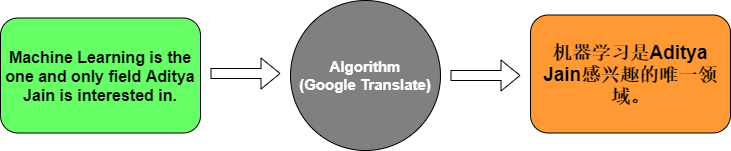

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5714 - loss: 2.4832

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5714 - loss: 2.4832 - val_accuracy: 0.0000e+00 - val_loss: 2.4856


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5714 - loss: 2.4741

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5714 - loss: 2.4741 - val_accuracy: 0.0000e+00 - val_loss: 2.4878


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8571 - loss: 0.5209 - val_accuracy: 0.0000e+00 - val_loss: 5.4059


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step - accuracy: 0.7143 - loss: 1.8471

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.7143 - loss: 1.8471


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step


Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

**1. What does the Embedding layer do to a word index?**

It converts the word index (a single integer, for example `how` → 2) into a **dense vector of real numbers** (64 numbers in the model above). The layer is a table with one row for each word in the vocabulary (`input_dim = len(eng_word_index) + 1`, the +1 is for the padding index 0), and the word index is used to select its row. The values of the vectors are learned during training, so words that are used in a similar way get similar vectors. This is better than using the index itself, because the number 2 does not tell the model anything about the meaning of the word.

**2. What is the role of the Encoder LSTM?**

The encoder LSTM **reads the English sentence** (the embedding vectors) word by word from left to right. At every step it updates its memory (hidden state and cell state) with the new word and what it has read before. In the model above it returns only its last output (`LSTM(64)` without `return_sequences`), which is a vector of 64 numbers that **summarizes the meaning of the whole English sentence**. This vector is called the *context vector*. `RepeatVector` then copies this vector once for each position of the French sentence, so that the decoder receives it at every step.

**3. What does the Decoder LSTM do?**

The decoder LSTM **generates the French sentence** from the context vector. It has `return_sequences=True`, so it returns an output for **every time step** (one for each word position of the French sentence) and not only the last one. Each output contains the information needed to predict the French word at that position, and it also uses its memory of the previous steps, so the words are generated in the correct order. `TimeDistributed(Dense(...))` applies the same Dense layer to each of these outputs.

**4. Why do we use `softmax` in the final layer?**

The Dense layer returns one score for **every word in the French vocabulary**. `softmax` converts these scores into **probabilities between 0 and 1 that sum to 1**, so the output is a probability distribution over the French words at each position. This is needed because:
- the loss `sparse_categorical_crossentropy` compares the predicted probabilities with the correct word index, and
- during inference `np.argmax` chooses the word with the highest probability as the translated word.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Plan:** train an English → French **encoder-decoder (seq2seq) LSTM** on the Kaggle dataset.

The model in the lab gives the encoder summary to the decoder with `RepeatVector` and predicts every French word at once, so the decoder never sees which words it has already produced. For a real translation task I use the standard version of the same idea:
- The **encoder LSTM** reads the English sentence and passes its final states (`h`, `c`) to the decoder.
- The **decoder LSTM** generates the French sentence **word by word**. During training it receives the correct previous word (**teacher forcing**), and during inference it receives the word it predicted in the previous step.
- Special tokens `<start>` and `<end>` tell the decoder where a sentence begins and ends.

The layers are the same as in the lab (Embedding → LSTM → LSTM → Dense with softmax).

#### 1. Load the dataset

In [8]:
import pandas as pd

df = pd.read_csv("eng_-french.csv")
df.columns = ["english", "french"]

print("Number of sentence pairs:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicated pairs:", df.duplicated().sum())
display(df.sample(5, random_state=42))

Number of sentence pairs: 175621


Missing values: 0
Duplicated pairs: 0


,english,french
2785,Take a seat.,Prends place !
29880,I wish Tom was here.,J'aimerais que Tom soit là.
53776,How did the audition go?,Comment s'est passée l'audition ?
154386,I've no friend to talk to about my problems.,Je n'ai pas d'ami avec lequel je puisse m'entr...
149823,I really like this skirt. Can I try it on?,"J'aime beaucoup cette jupe, puis-je l'essayer ?"


#### 2. Clean the sentences
Lowercase, separate the punctuation from the words and remove unusual characters. French accents (é, è, à, ç, ...) are kept because they are part of the words.

In [9]:
import re
import unicodedata

def clean_sentence(sentence):
    sentence = unicodedata.normalize("NFC", sentence).lower().strip()
    sentence = sentence.replace("’", "'").replace(" ", " ").replace(" ", " ")  # same apostrophe and space everywhere
    sentence = re.sub(r"([?.!,])", r" \1 ", sentence)              # put a space around punctuation, so it becomes a token
    sentence = re.sub(r"[^a-zà-ÿ0-9?.!,'\- ]+", " ", sentence)  # keep letters (also French accents), numbers and punctuation
    sentence = re.sub(r"\s+", " ", sentence).strip()
    return sentence

df = df.drop_duplicates()
df["english"] = df["english"].apply(clean_sentence)
df["french"] = df["french"].apply(clean_sentence)

# Keep short and medium sentences (up to 10 tokens), long sentences are rare and need much more training time
MAX_LEN = 10
df = df[(df["english"].str.split().str.len() <= MAX_LEN) & (df["french"].str.split().str.len() <= MAX_LEN)]

# Use a random sample of 30,000 pairs so the model can be trained on a normal CPU
df = df.sample(30000, random_state=42).reset_index(drop=True)

# Add a start and an end token to every French sentence: the decoder starts from <start> and stops at <end>
df["french"] = "<start> " + df["french"] + " <end>"

print("Pairs used for training and testing:", len(df))
display(df.head())

Pairs used for training and testing: 30000


,english,french
0,i know who my enemy is .,<start> je sais qui est mon ennemi . <end>
1,have you sold it yet ?,<start> l'as-tu déjà vendu ? <end>
2,i didn't want to believe it .,<start> je ne voulais pas le croire . <end>
3,i've made this trip a thousand times .,<start> j'ai fait ce voyage un millier de fois...
4,don't look so shocked .,<start> n'ayez pas l'air si choqués ! <end>


#### 3. Tokenize and pad (same as in the lab)

In [10]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# filters="" because the punctuation was already separated and the tokens <start> / <end> must be kept
tokenizer_eng = Tokenizer(filters="")
tokenizer_eng.fit_on_texts(df["english"])
tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(df["french"])

eng_vocab_size = len(tokenizer_eng.word_index) + 1   # +1 because index 0 is used for padding
frn_vocab_size = len(tokenizer_frn.word_index) + 1

# padding="post" puts the zeros at the end, so the sentences start at the first time step
eng_padded = pad_sequences(tokenizer_eng.texts_to_sequences(df["english"]), padding="post")
frn_padded = pad_sequences(tokenizer_frn.texts_to_sequences(df["french"]), padding="post")

print("English vocabulary size:", eng_vocab_size)
print("French vocabulary size :", frn_vocab_size)
print("English padded shape   :", eng_padded.shape)
print("French padded shape    :", frn_padded.shape)
print("\nExample:", df["english"][0], "->", eng_padded[0])
print("Example:", df["french"][0], "->", frn_padded[0])

English vocabulary size: 7105
French vocabulary size : 12598
English padded shape   : (30000, 10)
French padded shape    : (30000, 12)

Example: i know who my enemy is . -> [   2   32   88   25 1154    8    1    0    0    0]
Example: <start> je sais qui est mon ennemi . <end> -> [   1    4   71   40   16   42 2813    3    2    0    0    0]


#### 4. Train-test split and decoder input / target

In [11]:
from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.1, random_state=42)

# Teacher forcing: the decoder gets the correct French sentence shifted by one word,
# and it learns to predict the next word at every step
decoder_input_train = frn_train[:, :-1]    # <start> je suis ...
decoder_target_train = frn_train[:, 1:]    # je suis ... <end>
decoder_input_test = frn_test[:, :-1]
decoder_target_test = frn_test[:, 1:]

print("Training pairs:", len(eng_train))
print("Testing pairs :", len(eng_test))
print("\nDecoder input :", tokenizer_frn.sequences_to_texts([decoder_input_train[0]])[0])
print("Decoder target:", tokenizer_frn.sequences_to_texts([decoder_target_train[0]])[0])

Training pairs: 27000
Testing pairs : 3000

Decoder input : <start> il manque un lave-vaisselle dans la cuisine . <end>
Decoder target: il manque un lave-vaisselle dans la cuisine . <end>


#### 5. Build the encoder-decoder model
`mask_zero=True` tells the LSTMs and the loss to ignore the padding zeros.

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)
EMBEDDING_DIM = 128
UNITS = 256

# Encoder: reads the English sentence and summarizes it in its final states (h, c)
encoder_inputs = layers.Input(shape=(None,), name="english_input")
encoder_embedding = layers.Embedding(eng_vocab_size, EMBEDDING_DIM, mask_zero=True, name="english_embedding")(encoder_inputs)
_, state_h, state_c = layers.LSTM(UNITS, return_state=True, name="encoder_lstm")(encoder_embedding)
encoder_states = [state_h, state_c]

# Decoder: starts from the encoder states and generates the French sentence word by word
decoder_inputs = layers.Input(shape=(None,), name="french_input")
decoder_embedding_layer = layers.Embedding(frn_vocab_size, EMBEDDING_DIM, mask_zero=True, name="french_embedding")
decoder_lstm = layers.LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
decoder_dense = layers.Dense(frn_vocab_size, activation="softmax", name="output")

decoder_outputs, _, _ = decoder_lstm(decoder_embedding_layer(decoder_inputs), initial_state=encoder_states)
decoder_outputs = decoder_dense(decoder_outputs)

model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_input        │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_embedding   │ (None, None, 128) │    909,440 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_embedding    │ (None, None, 128) │  1,612,544 │ french_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ english_embeddin… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    394,240 │ french_embedding… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None,      │  3,237,686 │ decoder_lstm[0][… │
│                     │ 12598)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,548,150 (24.98 MB)

 Trainable params: 6,548,150 (24.98 MB)

 Non-trainable params: 0 (0.00 B)

#### 6. Train the model

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop when the validation loss does not improve for 2 epochs and keep the best weights
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit([eng_train, decoder_input_train], decoder_target_train,
                    epochs=25, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=2)

Epoch 1/25


190/190 - 45s - 236ms/step - accuracy: 0.2647 - loss: 5.3183 - val_accuracy: 0.3619 - val_loss: 4.4594


Epoch 2/25


190/190 - 51s - 268ms/step - accuracy: 0.3687 - loss: 4.2041 - val_accuracy: 0.3757 - val_loss: 4.1540


Epoch 3/25


190/190 - 55s - 291ms/step - accuracy: 0.3891 - loss: 3.8973 - val_accuracy: 0.4097 - val_loss: 3.9056


... (38 outputs left out)

Epoch 23/25


190/190 - 55s - 287ms/step - accuracy: 0.6944 - loss: 1.3653 - val_accuracy: 0.5671 - val_loss: 2.8409


Epoch 24/25


190/190 - 54s - 284ms/step - accuracy: 0.7076 - loss: 1.2988 - val_accuracy: 0.5668 - val_loss: 2.8434


#### 7. Evaluate the model

In [14]:
loss, accuracy = model.evaluate([eng_test, decoder_input_test], decoder_target_test, verbose=0)
print(f"Test Loss    : {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss    : 2.7710
Test Accuracy: 0.5659


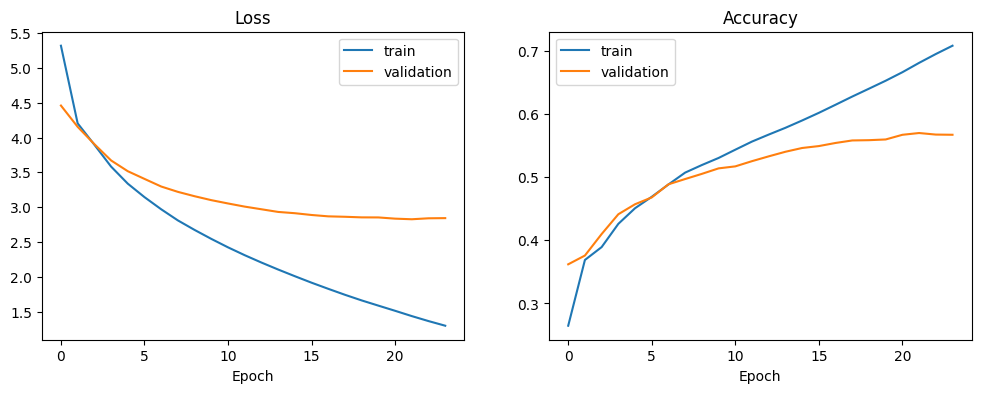

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.show()

#### 8. Translate new sentences (inference)
The encoder reads the English sentence once, then the decoder predicts one French word at a time, starting with `<start>`, until it predicts `<end>`.

In [16]:
# Inference models: the trained layers are reused, but the decoder now predicts one word at a time
encoder_model = Model(encoder_inputs, encoder_states)

decoder_state_h = layers.Input(shape=(UNITS,))
decoder_state_c = layers.Input(shape=(UNITS,))
decoder_step_outputs, step_h, step_c = decoder_lstm(decoder_embedding_layer(decoder_inputs),
                                                    initial_state=[decoder_state_h, decoder_state_c])
decoder_model = Model([decoder_inputs, decoder_state_h, decoder_state_c],
                      [decoder_dense(decoder_step_outputs), step_h, step_c])

start_id = tokenizer_frn.word_index["<start>"]
end_id = tokenizer_frn.word_index["<end>"]

def translate_sentence(sentence, max_words=MAX_LEN + 2):
    sequence = tokenizer_eng.texts_to_sequences([clean_sentence(sentence)])
    padded_sequence = pad_sequences(sequence, padding="post")
    h, c = encoder_model.predict(padded_sequence, verbose=0)    # 1. encode the English sentence

    word_id = start_id
    translated_words = []
    for _ in range(max_words):                                   # 2. generate the French words one by one
        probabilities, h, c = decoder_model.predict([np.array([[word_id]]), h, c], verbose=0)
        word_id = int(np.argmax(probabilities[0, -1]))           # the word with the highest probability
        if word_id == end_id or word_id == 0:                    # 3. stop at <end>
            break
        translated_words.append(tokenizer_frn.index_word[word_id])
    return " ".join(translated_words)

# Sentences from the test set (the model did not see them during training)
for i in range(10):
    english = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    reference = tokenizer_frn.sequences_to_texts([frn_test[i]])[0].replace("<start> ", "").replace(" <end>", "")
    print(f"English    : {english}")
    print(f"Reference  : {reference}")
    print(f"Translation: {translate_sentence(english)}\n")

English    : i need a map .
Reference  : il me faut une carte .


Translation: j'ai besoin de vous aider .

English    : we need something a bit more subtle .
Reference  : il nous faut quelque chose d'un peu plus subtil .


Translation: nous avons besoin de parler de une question de tom .

English    : it made sense .
Reference  : ça avait du sens .


Translation: ça s'est produit .

English    : that guy is a bandit .
Reference  : ce type est un bandit .


Translation: ce garçon est un homme .

English    : he was a bit late .
Reference  : il était un peu en retard .


Translation: il a un peu de temps .

English    : we sat face to face with executives .
Reference  : nous étions assis face aux cadres .


Translation: nous avons parlé de l'argent à tom .

English    : tom is no longer in our club .
Reference  : tom n'appartient plus à notre club .


Translation: tom n'est pas à boston dans une voiture .

English    : many small companies went bankrupt .
Reference  : de nombreuses petites entreprises ont fait faillite .


Translation: de nombreux parents sont trop tôt .

English    : it affects all of us .
Reference  : ça affecte l'ensemble d'entre nous .


Translation: ce n'est pas un jour .

English    : what are these charges for ?
Reference  : à quoi correspondent ces montants ?


Translation: quel est le problème ?



#### 9. BLEU score
Accuracy only checks the next word when the correct previous words are given. **BLEU** checks the full translations that the model generates by itself, so it is the usual metric for machine translation.

In [17]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# BLEU compares the words of the model translation with the reference translation (0 = bad, 1 = perfect)
references, predictions = [], []
for i in range(500):
    english = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    reference = tokenizer_frn.sequences_to_texts([frn_test[i]])[0].split()[1:-1]   # remove <start> and <end>
    references.append([reference])
    predictions.append(translate_sentence(english).split())

bleu = corpus_bleu(references, predictions, smoothing_function=SmoothingFunction().method1)
print(f"BLEU score on 500 test sentences: {bleu:.4f}")

BLEU score on 500 test sentences: 0.0600


#### 10. Use case: e-commerce sentences

In [18]:
# Use case: e-commerce sentences (product listings and customer reviews)
shop_sentences = ["This product is very good.",
                  "I like this phone.",
                  "The price is too high.",
                  "Is this book available?",
                  "I want to buy a new car.",
                  "This shirt is too big for me.",
                  "It was delivered yesterday.",
                  "I am very happy with this computer."]

for sentence in shop_sentences:
    print(f"{sentence:<38} -> {translate_sentence(sentence)}")

This product is very good.             -> ce sont très très bon .


I like this phone.                     -> j'aime cette permission .


The price is too high.                 -> le chien est très trompeur .


Is this book available?                -> est-ce que ce livre a une seconde ?


I want to buy a new car.               -> je veux une tasse de thé .


This shirt is too big for me.          -> ce chapeau est trop pour toi .


It was delivered yesterday.            -> c'était la vérité .


I am very happy with this computer.    -> je suis très fier de votre part .


**Result:**

1. **Data:** the Kaggle dataset has **175,621** English-French pairs with no missing values. After cleaning, I kept the sentences with at most 10 tokens and used a random sample of **30,000 pairs** so the model can be trained on a normal CPU (27,000 for training, 3,000 for testing). The vocabularies are **7,105** English words and **12,598** French words (French has more word forms, e.g. *grand / grande / grands / grandes*).
2. **Model:** an encoder-decoder LSTM (Embedding 128 + LSTM 256 for each side, with a softmax Dense output over the French vocabulary), about **6.5 million** parameters, trained with teacher forcing.
3. **Training:** the loss goes down in every epoch. `EarlyStopping` stopped the training after epoch 24, because the validation loss had not improved since epoch **22** (2.83), and the weights of epoch 22 were restored. After that the training accuracy keeps rising but the validation accuracy does not, which means the model starts to **overfit**.
4. **Evaluation:**
   - **Test accuracy = 56.6 %**: the model predicts the correct next French word about 57 % of the time (when the correct previous words are given).
   - **BLEU = 0.06** on 500 test sentences, when the model generates the full translation by itself.
5. **Translations:** the model produces **correct French grammar** and gets the structure of the sentence right in many cases:
   - *that guy is a bandit* → *ce garçon est un homme* (correct structure, *ce ... est un ...*)
   - *many small companies went bankrupt* → *de nombreux parents ...* (correct start)
   - *is this book available?* → *est-ce que ce livre ...* (correct question form and the word *livre*)
   - *i like this phone* → *j'aime cette ...*

   But it often chooses **wrong content words** (*le chien* instead of *le prix*, *une tasse de thé* instead of *une nouvelle voiture*). It replaces words it does not know well with common words from the training data (*tom*, *boston*, *temps*).

**Why are the translations not good enough for the company yet?**
- **Small data:** 30,000 pairs for 12,598 French words, so most words appear only a few times. The dataset also has very few sentences about shopping (it is mostly everyday sentences like *"Tom is ..."*).
- **Simple model:** the encoder compresses the whole English sentence into **one** vector (`h`, `c`), which loses information, especially for longer sentences. This is why *attention* (Lab 11) was introduced: the decoder can look at every English word while it generates each French word.
- **Limited training:** a CPU, 22 epochs, and greedy decoding (always the most probable word).

**How to make it good enough for product listings and reviews:** train on the full dataset (175k pairs) on a GPU, add **attention** or use a **Transformer**, add e-commerce data (product descriptions, reviews), and use beam search. In practice a company would **fine-tune a pre-trained translation model** (e.g. MarianMT `Helsinki-NLP/opus-mt-en-fr`), which was trained on millions of sentence pairs, and use the model from this task as a baseline.

__________________________________________________________________________________________

# What I Learned from Lab 10

In this lab I learned about **Machine Translation (MT)**: automatically translating text from one language to another. It is difficult because of ambiguity (*bank*), idioms (*raining cats and dogs*) and languages with little data.

### Neural Machine Translation
- A single neural network learns both languages from a large set of sentence pairs, without manual rules.
- The text is prepared with `Tokenizer` (each word gets an index, 0 is reserved for padding) and `pad_sequences` (all sentences get the same length).
- **Embedding** converts each word index into a learned vector, the **encoder LSTM** reads the source sentence and summarizes it, the **decoder LSTM** generates the target sentence, and **softmax** gives a probability for each word of the target vocabulary.

### Task 2: English → French Translation
- The French sentences get `<start>` and `<end>` tokens, and the decoder is trained with **teacher forcing**: it receives the correct previous word and predicts the next one.
- `mask_zero=True` makes the model ignore the padding, and `EarlyStopping` stops the training when the validation loss stops improving.
- For inference the encoder and the decoder are separated, and the decoder generates the translation one word at a time until it predicts `<end>`.
- The model reached **56.6 %** test accuracy and a **BLEU score of 0.06**. It learned French grammar and sentence structure, but it often chose the wrong words, because 30,000 sentence pairs are not enough data and one context vector cannot hold all the information of a sentence.
- **BLEU** is the standard metric for machine translation, because accuracy alone does not show how good the full generated translation is.
- To use machine translation in a real product, you need much more data, attention / Transformers, or a pre-trained translation model.